# Contextual grid-path semi-bandit

A compact comparison of `SquareCB.comb`, `SquareCB.lin`, epsilon-greedy, VCEE, and LinUCB using the implementations in `src/algorithms`.

The base arms are the down/right edges of an $s\times s$ grid. At round $t$, a context $x_t\in[0,1]^2$ arrives, the learner selects a monotone top-left to bottom-right path $A_t$, and observes the Bernoulli rewards of its edges. Every method sees the same contextual edge features $\phi(x_t,e)$. The mean reward is a Gaussian bump centred at $c(x_t)=x_t$, so the high-reward region of the grid *moves* with the context — and, being a bump, it is not linear in $\phi$. Every learner here is therefore misspecified by construction; see [`GRID_PATH_REWARD_MODEL.md`](GRID_PATH_REWARD_MODEL.md).

Performance is cumulative pseudo-regret against the context-optimal path,

$$R_T=\sum_{t=1}^T\left[\max_{A\in\mathcal A}\sum_{e\in A}\mu_e(x_t)-\sum_{e\in A_t}\mu_e(x_t)\right].$$

The environment uses dynamic programming for the exact path oracle. The algorithm classes are reused directly; small subclasses only replace unconstrained top-$L$ action selection by feasible-path selection.

In [9]:
import contextlib
import io
import math
import os
import sys
import warnings
from dataclasses import dataclass
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.linear_model import LinearRegression

SRC = os.path.join(os.getcwd(), "src")
assert os.path.isdir(SRC), "Run this notebook from the repository root."
if SRC not in sys.path:
    sys.path.insert(0, SRC)

import Argmax
from Context import Context
from Policy import RegressionPolicy
from algorithms import EpsGreedy as BaseEpsGreedy
from algorithms import LinUCB as BaseLinUCB
from algorithms import MiniMonster, SquareCB as BaseSquareCB
from algorithms import SquareCBLin as BaseSquareCBLin
from algorithms.sampling_oracle.logdet_sampler import _solve_logdet

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False})


@dataclass(frozen=True)
class ExperimentConfig:
    grid_size: int = 5
    noncontext_x: tuple = (0.2, 0.8)
    T: int = 1_000
    n_seeds: int = 8
    seed0: int = 2026
    n_jobs: int = -1
    output_dir: str = "results/grid_path_simple"

    # SquareCB knobs. These are the notebook's own defaults, NOT the tuned
    # values in tune/sqcb_lin_optima.json (gamma_multiplier 3-30, y_scale 1.0,
    # normalize_features True). normalize_features in particular is not a
    # neutral preprocessing switch here: dividing phi by ||phi|| injects
    # sqrt(1 + is_down + row^2 + col^2), which lifts SquareCB out of the
    # rank-1 path geometry the other arms are confined to. See
    # GRID_PATH_REWARD_MODEL.md section 6.3.
    gamma_multiplier: float = 1.0
    normalize_features: bool = False
    y_scale_lin: Optional[float] = None      # None -> env.L (the slate size)

    # gamma-multiplier sweep (its own, smaller replication budget)
    gamma_grid: tuple = (0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0)
    sweep_oracles: tuple = ("Lin", "GB5", "XGB5")
    sweep_seeds: int = 4


CFG = ExperimentConfig()
CFG

ExperimentConfig(grid_size=5, noncontext_x=(0.2, 0.8), T=1000, n_seeds=8, seed0=2026, n_jobs=-1, output_dir='results/grid_path_simple', gamma_multiplier=1.0, normalize_features=False, y_scale_lin=None, gamma_grid=(0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0), sweep_oracles=('Lin', 'GB5', 'XGB5'), sweep_seeds=4)

## Environment

Each edge $e$ carries the fixed attributes

$$a_e=\big(1,\ \mathrm{is\_down}_e,\ \mathrm{row}_e,\ \mathrm{col}_e\big),$$

where $\mathrm{is\_down}_e\in\{0,1\}$ marks a downward edge and $(\mathrm{row}_e,\mathrm{col}_e)\in[0,1]^2$ is the normalised position of the edge's source node — $(0,0)$ is the top-left corner, $(1,1)$ the bottom-right. The learner receives the tensor-product features

$$\phi(x,e)=\operatorname{vec}\!\left(a_e\,[1,x_1,x_2]^\top\right)\in\mathbb{R}^{12}.$$

The context is $x\sim\mathrm{Unif}([0,1]^2)$ and the Bernoulli mean of each edge is a Gaussian bump centred at $c(x)=x$:

$$\mu(x,a_e)\;=\;0.25\;+\;0.04\,\mathrm{is\_down}_e\;+\;0.45\exp\!\left(-\frac{\big\lVert(\mathrm{row}_e,\mathrm{col}_e)-c(x)\big\rVert_2^2}{2\cdot 0.35^2}\right)\;\in\;[0.25,\ 0.74].$$

The reward function plants a high-reward region around $c(x)$: nearby edges have expected reward up to $0.74$, while edges far from the centre fall back to the baseline $0.25$. The context tells the learner where this region currently sits.

Because the bump is not linear in $\phi$, no linear regressor can represent $\mu$. The floor this puts on every method in this notebook is quantified in `GRID_PATH_REWARD_MODEL.md` §6.

In [10]:
class GridPathEnv:
    """Contextual Bernoulli semi-bandit on monotone grid paths.

    The mean of edge e under context x is a Gaussian bump centred at c(x) = x,
        mu(x, a_e) = LO + DOWN * is_down_e
                     + AMP * exp(-||(row_e, col_e) - x||^2 / (2 * WIDTH^2)),
    which is *not* linear in the features phi(x, e) the learners regress on.
    """

    LO, DOWN, AMP, WIDTH = 0.25, 0.04, 0.45, 0.35

    def __init__(self, cfg, seed):
        self.cfg = cfg
        self.s = cfg.grid_size
        self.start, self.end = (0, 0), (self.s - 1, self.s - 1)
        self.nodes = [(i, j) for i in range(self.s) for j in range(self.s)]
        self.edges = []
        for i, j in self.nodes:
            if i + 1 < self.s:
                self.edges.append(((i, j), (i + 1, j)))
            if j + 1 < self.s:
                self.edges.append(((i, j), (i, j + 1)))
        self.eidx = {edge: k for k, edge in enumerate(self.edges)}

        self.K = len(self.edges)
        self.L = 2 * (self.s - 1)
        self.weight = np.ones(self.L)
        self.rng = np.random.default_rng(seed)

        attrs = np.empty((self.K, 4))
        for k, ((i, j), (i2, _)) in enumerate(self.edges):
            row, col = i / (self.s - 1), j / (self.s - 1)
            attrs[k] = (1.0, float(i2 > i), row, col)
        self.attrs = attrs
        self.pos = attrs[:, 2:4]
        self.d = attrs.shape[1] * 3
        self.paths = self._enumerate_paths()
        self.N = len(self.paths)
        self.incidence = np.zeros((self.N, self.K))
        self.incidence[np.repeat(np.arange(self.N), self.L), self.paths.ravel()] = 1.0
        self.uniform_marginals = self.incidence.mean(axis=0)
        self.curr_mu = self.curr_r = self.curr_opt = None
        self.t = 0

        # The Gaussian factor lies in (0, 1], so mu is bounded analytically;
        # no sampling needed to certify the Bernoulli parameter.
        bounds = (self.LO, self.LO + self.DOWN + self.AMP)
        if bounds[0] < 0 or bounds[1] > 1:
            raise ValueError("The Bernoulli mean model must remain in [0, 1].")
        self.mean_range = bounds

    def features_at(self, x):
        zeta = np.r_[1.0, np.asarray(x)]
        return (self.attrs[:, :, None] * zeta[None, None, :]).reshape(self.K, self.d)

    def means_at(self, x):
        offset = self.pos - np.asarray(x, dtype=float)
        bump = np.exp(-(offset ** 2).sum(axis=1) / (2.0 * self.WIDTH ** 2))
        return self.LO + self.DOWN * self.attrs[:, 1] + self.AMP * bump

    def _enumerate_paths(self):
        paths, stack = [], [(self.start, [])]
        while stack:
            (i, j), path = stack.pop()
            if (i, j) == self.end:
                paths.append(path)
                continue
            for nxt in ((i + 1, j), (i, j + 1)):
                edge = ((i, j), nxt)
                if edge in self.eidx:
                    stack.append((nxt, path + [self.eidx[edge]]))
        return np.asarray(paths, dtype=int)

    def best_path(self, scores):
        values, choice = {self.end: 0.0}, {}
        for i in range(self.s - 1, -1, -1):
            for j in range(self.s - 1, -1, -1):
                if (i, j) == self.end:
                    continue
                candidates = []
                for nxt in ((i + 1, j), (i, j + 1)):
                    edge = ((i, j), nxt)
                    if edge in self.eidx:
                        candidates.append((scores[self.eidx[edge]] + values[nxt], nxt))
                values[(i, j)], choice[(i, j)] = max(candidates, key=lambda x: x[0])
        path, node = [], self.start
        while node != self.end:
            nxt = choice[node]
            path.append(self.eidx[(node, nxt)])
            node = nxt
        return np.asarray(path, dtype=int)

    def get_new_context(self):
        x = self.rng.uniform(0.0, 1.0, 2)
        self.curr_mu = self.means_at(x)
        self.curr_r = self.rng.binomial(1, self.curr_mu).astype(float)
        self.curr_opt = self.best_path(self.curr_mu)
        self.t += 1
        return Context(f"grid-{self.t}", self.features_at(x), self.K, self.L)

    def check_path(self, action):
        action = np.asarray(action, dtype=int)
        if action.shape != (self.L,):
            raise ValueError(f"Expected {self.L} edges, got {action.shape}.")
        node = self.start
        for edge_id in action:
            u, v = self.edges[edge_id]
            if u != node:
                raise ValueError("Selected edges do not form a connected path.")
            node = v
        if node != self.end:
            raise ValueError("Path does not reach the bottom-right node.")
        return action

    def get_slate_reward(self, action):
        return float(self.curr_r[self.check_path(action)].sum())

    def get_base_rewards(self, action):
        return self.curr_r[np.asarray(action, dtype=int)]

    def get_best_reward(self):
        return float(self.curr_mu[self.curr_opt].sum())


env = GridPathEnv(CFG, CFG.seed0)


def reference_regrets(env, contexts):
    """Per-round pseudo-regret of the two references the curves are read against.

    "best linear predictor" fits theta by OLS of mu on phi over `contexts` and plays
    its DP-argmax path: the misspecification floor no linear oracle can beat, however
    much data it sees. "uniform-random path" is the no-learning reference.
    """
    contexts = np.atleast_2d(contexts)
    phi = np.stack([env.features_at(x) for x in contexts])
    mu = np.stack([env.means_at(x) for x in contexts])
    theta, *_ = np.linalg.lstsq(phi.reshape(-1, env.d), mu.ravel(), rcond=None)
    values = mu @ env.incidence.T
    linear = (phi @ theta) @ env.incidence.T
    best = values.max(axis=1)
    return {
        "best linear predictor":
            float((best - values[np.arange(len(contexts)), linear.argmax(axis=1)]).mean()),
        "uniform-random path": float((best - values.mean(axis=1)).mean()),
    }


rng = np.random.default_rng(0)
sample = rng.uniform(0.0, 1.0, (20_000, 2))
path_values = np.stack([env.means_at(x) for x in sample]) @ env.incidence.T
contextual_refs = reference_regrets(env, sample)
print(f"grid={env.s}x{env.s}, K={env.K} edges, L={env.L} edges/path, "
      f"paths={env.N}, d={env.d}")
print(f"mean range=[{env.mean_range[0]:.2f}, {env.mean_range[1]:.2f}], "
      f"context value="
      f"{path_values.max(axis=1).mean() - path_values.mean(axis=0).max():.3f}/round, "
      f"optimal paths observed={np.unique(path_values.argmax(axis=1)).size}/{env.N}")
print("reference pseudo-regret per round: "
      + ", ".join(f"{k}={v:.3f}" for k, v in contextual_refs.items()))

grid=5x5, K=40 edges, L=8 edges/path, paths=70, d=12
mean range=[0.25, 0.74], context value=0.419/round, optimal paths observed=8/70
reference pseudo-regret per round: best linear predictor=0.387, uniform-random path=0.516


### The grid and its edge means

Each panel is one context. Edges are coloured by $\mu(x,a_e)$ on the shared analytic scale $[0.25,0.74]$, the star marks the bump centre $c(x)=x$, the red rings mark the start and end nodes, and the red band traces the DP-optimal path $A^*(x)$.

The optimal path bends toward wherever the context puts the bump, and it is generally an *interior* path — something a mean that is linear in position can never produce (§1.1 of `GRID_PATH_REWARD_MODEL.md`). When $c(x)$ lies on the diagonal the grid's row$\leftrightarrow$column reflection is an exact symmetry of the path values, so mirror-image paths tie; that is why the two staircases `DRDRDRDR` and `RDRDRDRD` end up optimal on near-equal shares of contexts.

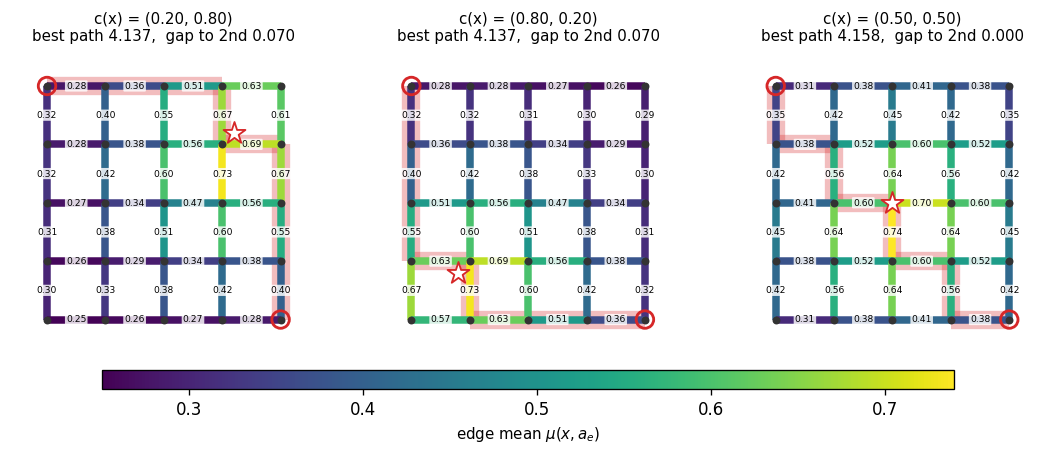

In [11]:
from matplotlib.collections import LineCollection


def draw_grid_rewards(env, contexts, filename="grid_rewards.png", annotate=True):
    """Edge means mu(x, a_e) on the grid, with the context-optimal path highlighted."""
    lo, hi = env.mean_range
    norm = plt.Normalize(lo, hi)
    cmap = plt.get_cmap("viridis")
    segments = [[(j, -i), (j2, -i2)] for (i, j), (i2, j2) in env.edges]
    nodes = np.array([(j, -i) for i, j in env.nodes])

    fig, axes = plt.subplots(1, len(contexts), figsize=(3.7 * len(contexts), 4.1),
                             squeeze=False)
    for ax, x in zip(axes[0], contexts):
        x = np.asarray(x, dtype=float)
        mu = env.means_at(x)
        values = np.sort(env.incidence @ mu)
        ax.add_collection(LineCollection([segments[k] for k in env.best_path(mu)],
                                         colors="#d62728", linewidths=11,
                                         alpha=0.30, zorder=1))
        ax.add_collection(LineCollection(segments, colors=cmap(norm(mu)),
                                         linewidths=4.5, zorder=2))
        ax.scatter(nodes[:, 0], nodes[:, 1], s=14, color="#333333", zorder=3)
        for node in (env.start, env.end):
            ax.scatter(node[1], -node[0], s=110, facecolor="none",
                       edgecolor="#d62728", lw=1.7, zorder=4)
        ax.scatter(x[1] * (env.s - 1), -x[0] * (env.s - 1), marker="*", s=190,
                   color="white", edgecolor="#d62728", lw=1.1, zorder=6)
        if annotate:
            for k, ((x0, y0), (x1, y1)) in enumerate(segments):
                ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"{mu[k]:.2f}",
                        ha="center", va="center", fontsize=5.5, zorder=5,
                        bbox=dict(boxstyle="round,pad=0.12", fc="white",
                                  ec="none", alpha=0.82))
        ax.set_title(f"c(x) = ({x[0]:.2f}, {x[1]:.2f})\n"
                     f"best path {values[-1]:.3f},  gap to 2nd {values[-1] - values[-2]:.3f}",
                     fontsize=9)
        ax.set_xlim(-0.6, env.s - 0.4)
        ax.set_ylim(-env.s + 0.4, 0.6)
        ax.set_aspect("equal")
        ax.axis("off")

    bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[0],
                       orientation="horizontal", fraction=0.05, pad=0.04, aspect=45)
    bar.set_label(r"edge mean $\mu(x, a_e)$", fontsize=9)
    os.makedirs(CFG.output_dir, exist_ok=True)
    fig.savefig(os.path.join(CFG.output_dir, filename), dpi=180, bbox_inches="tight")
    plt.show()


draw_grid_rewards(env, [CFG.noncontext_x, (0.8, 0.2), (0.5, 0.5)])

## Algorithms

| label | implementation reused | path-specific change | feedback |
|---|---|---|---|
| `SquareCB.comb` | `algorithms.SquareCB` | Frank–Wolfe over the path polytope | edge rewards |
| `SquareCB.lin` | `algorithms.SquareCBLin` | log-det distribution over feasible paths | aggregate path reward |
| `Epsilon-greedy` | `algorithms.EpsGreedy` | random or predicted-best path | edge rewards |
| `VCEE` | `algorithms.MiniMonster` | path-valued policies and uniform-path smoothing | edge rewards |
| `LinUCB` | `algorithms.LinUCB` | DP-best path under edge UCB indices | edge rewards |

All regression oracles are linear, and therefore all of them are misspecified against the Gaussian bump. What the comparison measures is the exploration scheme, under an approximation error the five methods share. Uniform exploration means a uniformly sampled feasible path, whose exact edge marginals are precomputed by the environment.

In [12]:
class PathLinUCB(BaseLinUCB):
    def get_action(self, context):
        features = np.asarray(context.get_ld_features())
        width = np.sqrt(np.einsum("ki,ij,kj->k", features, np.asarray(self.Cinv), features))
        scores = features @ np.asarray(self.weights).ravel() + np.sqrt(self.d) * self.delta * width
        scores += 1e-10 * np.random.standard_normal(self.B.K)
        return self.B.best_path(scores)


class PathSquareCBLin(BaseSquareCBLin):
    def init(self, T, params=None):
        super().init(T, params)
        self._paths, self._incidence = self.B.paths, self.B.incidence

    def get_action(self, context):
        features = np.asarray(context.get_ld_features(), dtype=float)
        scores = self._build_model(features.shape[1]).predict(features)
        q = _solve_logdet(self._incidence, scores, self._gamma())
        index = int(self.rng.choice(len(q), p=q))
        self.imp_weights = q @ self._incidence
        self.action = self._paths[index].copy()
        return self.action


class PathSquareCBComb(BaseSquareCB):
    FW_ITERS, FW_TOL = 60, 1e-4

    def init(self, T, params=None):
        super().init(T, params)
        self._paths, self._incidence = self.B.paths, self.B.incidence

    def get_action(self, context):
        features = np.asarray(context.get_ld_features(), dtype=float)
        scores = self._build_model(features.shape[1]).predict(features)
        gamma = self._gamma()
        q = np.full(self.B.N, 1.0 / self.B.N)
        marginals = q @ self._incidence
        for iteration in range(self.FW_ITERS):
            gradient = scores + 1.0 / (gamma * np.maximum(marginals, 1e-12))
            index = int(np.argmax(self._incidence @ gradient))
            vertex = self._incidence[index]
            if gradient @ (vertex - marginals) < self.FW_TOL:
                break
            step = 2.0 / (iteration + 3.0)  # keep all edge marginals positive
            q *= 1.0 - step
            q[index] += step
            marginals = (1.0 - step) * marginals + step * vertex
        index = int(self.rng.choice(self.B.N, p=q / q.sum()))
        self.imp_weights = marginals
        self.action = self._paths[index].copy()
        return self.action


In [13]:
class PathEpsGreedy(BaseEpsGreedy):
    def init(self, T, params=None):
        super().init(T, params or {})
        self._uniform = self.B.uniform_marginals

    def get_action(self, context):
        eps = min(1.0, self._get_eps())
        self.ber = np.random.binomial(1, eps)
        greedy = None
        if self.leader is not None:
            scores = self.leader.model.predict(context.get_ld_features())
            greedy = self.B.best_path(scores)
        self.imp_weights = self._uniform.copy()
        if greedy is not None:
            self.imp_weights *= eps
            self.imp_weights[greedy] += 1.0 - eps
        if greedy is None or self.ber:
            self.action = self.B.paths[np.random.randint(self.B.N)].copy()
            self.num_unif += 1
        else:
            self.action = greedy
        return self.action


class PathPolicy(RegressionPolicy):
    def __init__(self, model, env):
        super().__init__(model)
        self.env = env

    def get_action(self, context):
        return self.env.best_path(self.model.predict(context.get_ld_features()))

    def get_weighted_action(self, context, weight):
        return self.get_action(context)

    def get_all_actions(self, contexts, features=None):
        if not contexts:
            return []
        if features is None:
            features = np.vstack([x.get_ld_features() for x in contexts])
        predictions = self.model.predict(features)
        return [self.env.best_path(predictions[i * self.env.K:(i + 1) * self.env.K])
                for i in range(len(contexts))]


@contextlib.contextmanager
def path_argmax():
    stock = Argmax.argmax2

    def constrained(env, dataset, policy_type=None, learning_alg=None):
        policy = stock(env, dataset, policy_type=RegressionPolicy,
                       learning_alg=learning_alg)
        return PathPolicy(policy.model, env)

    Argmax.argmax2 = constrained
    try:
        yield
    finally:
        Argmax.argmax2 = stock


class PathVCEE(MiniMonster):
    def init(self, T, params=None):
        super().init(T, params or {})
        self._uniform = self.B.uniform_marginals

    def update(self, context, action, rewards, total_reward):
        with path_argmax():
            super().update(context, action, rewards, total_reward)

    def _marginalize(self, Q, context, predictions):
        marginals = np.zeros(self.B.K, dtype=np.longdouble)
        for policy, weight in Q:
            marginals[predictions[policy][context.get_name()]] += weight
        return ((1.0 - self._get_mu()) * marginals
                + self._get_mu() * self._uniform)

    def get_action(self, context):
        distribution, marginals = {}, np.zeros(self.B.K)
        for policy, weight in self.weights:
            distribution, marginals = self._update_dists(
                distribution, marginals, policy.get_action(context), weight)
        if self.leader is not None:
            residual = 1.0 - sum(weight for _, weight in self.weights)
            distribution, marginals = self._update_dists(
                distribution, marginals, self.leader.get_action(context), residual)
        self.imp_weights = ((1.0 - self._get_mu()) * marginals
                            + self._get_mu() * self._uniform)
        if self.leader is None or np.random.binomial(1, self._get_mu()):
            self.action = self.B.paths[np.random.randint(self.B.N)].copy()
            self.num_unif += 1
        else:
            items = list(distribution.items())
            probabilities = np.array([weight for _, weight in items], dtype=float)
            key = items[int(np.random.choice(len(items), p=probabilities / probabilities.sum()))][0]
            self.action = np.asarray(self._unhash_list(key), dtype=int)
        return self.action


def batch_linear_oracle():
    return LinearRegression()


# Oracle tag -> `make_oracle` name. Tags are what appears in arm labels and
# in the result tables' columns.
ORACLES = {"Lin": "linear", "GB2": "gb2", "GB5": "gb5",
           "XGB2": "xgb2", "XGB5": "xgb5"}
SQUARECB_FAMILIES = ("SquareCB.comb", "SquareCB.lin")
BASELINES = ("Epsilon-greedy", "VCEE", "LinUCB")

ALGORITHMS = tuple(f"{family}-{tag}" for family in SQUARECB_FAMILIES
                   for tag in ORACLES) + BASELINES


def split_arm(name):
    """'SquareCB.comb-XGB5' -> ('SquareCB.comb', 'XGB5'); 'LinUCB' -> ('LinUCB', '').

    Split on the LAST hyphen and only when the head is a SquareCB family, so
    that a hyphen inside a plain arm name ("Epsilon-greedy") is left alone.
    """
    family, _, tag = name.rpartition("-")
    if family in SQUARECB_FAMILIES:
        return family, tag
    return name, ""


def make_algorithm(name, env, seed, gamma_multiplier=None):
    family, tag = split_arm(name)
    if family in SQUARECB_FAMILIES:
        params = {
            "model_type": ORACLES[tag],
            "gamma_multiplier": (CFG.gamma_multiplier if gamma_multiplier is None
                                 else float(gamma_multiplier)),
            "normalize_features": CFG.normalize_features,
            "seed": seed,
        }
        if family == "SquareCB.comb":
            return PathSquareCBComb(env), params
        params["y_scale"] = env.L if CFG.y_scale_lin is None else CFG.y_scale_lin
        return PathSquareCBLin(env), params
    if name == "Epsilon-greedy":
        return PathEpsGreedy(env, learning_alg=batch_linear_oracle,
                             classification=False), {
            "eps": 0.05, "train_all": True, "weight": np.ones(env.L)}
    if name == "VCEE":
        return PathVCEE(env, learning_alg=batch_linear_oracle,
                        classification=False), {"mu": 1.0}
    if name == "LinUCB":
        return PathLinUCB(env), {"delta": 0.2, "schedule": 10}
    raise KeyError(name)


def run_one(name, cfg, seed, env_class=GridPathEnv, gamma_multiplier=None):
    env = env_class(cfg, seed)
    np.random.seed(seed)
    algorithm, params = make_algorithm(name, env, seed, gamma_multiplier)
    algorithm.verbose = False
    with contextlib.redirect_stdout(io.StringIO()):
        algorithm.init(cfg.T, params=params)

    regret = np.empty(cfg.T)
    reward = np.empty(cfg.T)
    optimal = np.empty(cfg.T, dtype=bool)
    for t in range(cfg.T):
        context = env.get_new_context()
        action = np.asarray(algorithm.get_action(context), dtype=int)
        total_reward = env.get_slate_reward(action)
        edge_rewards = env.get_base_rewards(action)
        algorithm.update(context, action, edge_rewards, total_reward)
        regret[t] = (env.curr_mu[env.curr_opt].sum()
                     - env.curr_mu[action].sum())
        reward[t] = total_reward
        optimal[t] = np.array_equal(action, env.curr_opt)
    return {"cum_regret": np.cumsum(regret),
            "cum_reward": np.cumsum(reward), "optimal": optimal}

In [14]:
seeds = range(CFG.seed0, CFG.seed0 + CFG.n_seeds)
jobs = [(name, seed) for name in ALGORITHMS for seed in seeds]
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="A worker stopped while some jobs.*")
    completed = Parallel(n_jobs=CFG.n_jobs)(
        delayed(run_one)(name, CFG, seed) for name, seed in jobs)
runs = {name: [] for name in ALGORITHMS}
for (name, _), result in zip(jobs, completed):
    runs[name].append(result)
print(f"Finished {len(ALGORITHMS)} algorithms x {CFG.n_seeds} seeds x "
      f"{CFG.T:,} rounds.")


Finished 13 algorithms x 8 seeds x 1,000 rounds.


## Results

Curves show mean cumulative pseudo-regret; shaded bands are 95% normal confidence intervals across seeds. The table also reports realized reward per round and the context-optimal path rate over the final 20% of rounds. Lower regret is better.


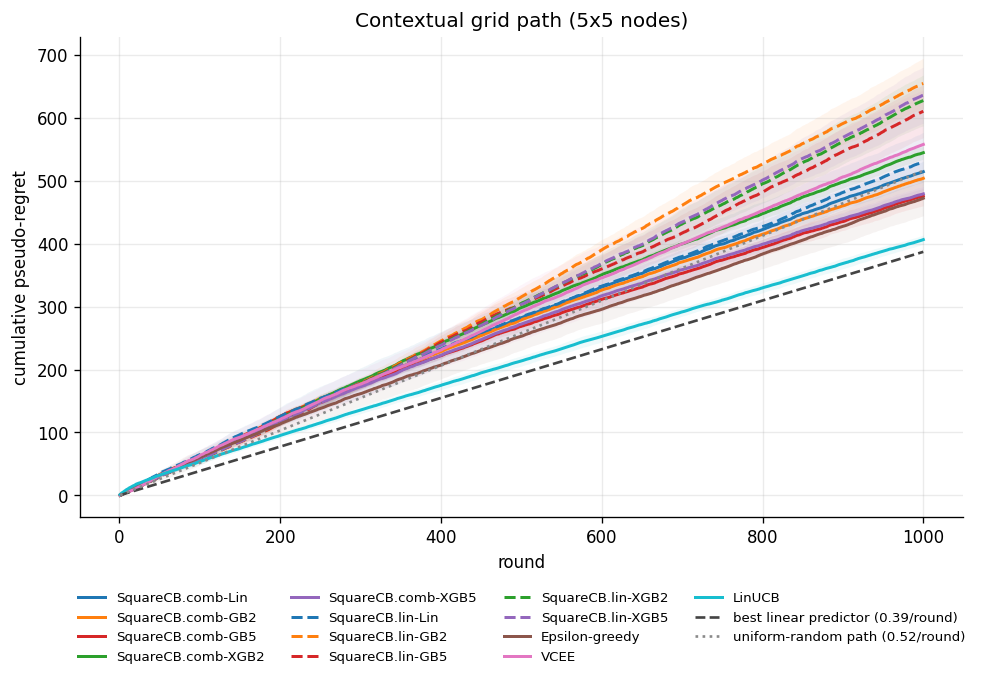

oracle,—,Lin,GB2,GB5,XGB2,XGB5
algorithm,,,,,,
SquareCB.comb,—,514.5,504.0,475.7,544.7,479.2
SquareCB.lin,—,530.6,654.6,610.6,627.6,635.9
Epsilon-greedy,472.3,—,—,—,—,—
VCEE,557.8,—,—,—,—,—
LinUCB,406.5,—,—,—,—,—


,final pseudo-regret,regret sd,reward / round,optimal-path rate (last 20%)
arm,,,,
LinUCB,406.5,10.4,3.610,7.2%
Epsilon-greedy,472.3,39.9,3.540,6.8%
SquareCB.comb-GB5,475.7,22.3,3.526,5.1%
SquareCB.comb-XGB5,479.2,12.4,3.516,5.2%
SquareCB.comb-GB2,504.0,17.6,3.504,4.4%
SquareCB.comb-Lin,514.5,23.8,3.502,11.9%
SquareCB.lin-Lin,530.6,66.9,3.450,5.1%
SquareCB.comb-XGB2,544.7,14.6,3.451,3.2%
VCEE,557.8,124.4,3.449,6.3%


In [15]:
# Colour encodes the regression oracle, line style the SquareCB variant, so
# "same oracle, different variant" and "same variant, different oracle" are
# both readable off the figure. The three non-SquareCB arms get their own
# colours and are always solid.
ORACLE_COLORS = {"Lin": "#1f77b4", "GB2": "#ff7f0e", "GB5": "#d62728",
                 "XGB2": "#2ca02c", "XGB5": "#9467bd"}
FAMILY_LS = {"SquareCB.comb": "-", "SquareCB.lin": "--"}
FAMILY_MARKER = {"SquareCB.comb": "o", "SquareCB.lin": "s"}
BASELINE_COLORS = {"Epsilon-greedy": "#8c564b", "VCEE": "#e377c2",
                   "LinUCB": "#17becf"}
ref_styles = {"best linear predictor": ("--", "#444444"),
              "uniform-random path": (":", "#8a8a8a")}
ORACLE_ORDER = ["—", "Lin", "GB2", "GB5", "XGB2", "XGB5"]
ALGO_ORDER = list(SQUARECB_FAMILIES) + list(BASELINES)


def style_for(name):
    family, tag = split_arm(name)
    if tag:
        return ORACLE_COLORS[tag], FAMILY_LS[family]
    return BASELINE_COLORS[name], "-"


def plot_results(experiment_runs, title, filename, refs=None):
    steps = np.arange(1, CFG.T + 1)
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    rows, tail = [], max(1, CFG.T // 5)
    for name in ALGORITHMS:
        reg = np.stack([run["cum_regret"] for run in experiment_runs[name]])
        rew = np.stack([run["cum_reward"] for run in experiment_runs[name]])
        hit = np.stack([run["optimal"] for run in experiment_runs[name]])
        mean = reg.mean(axis=0)
        se = reg.std(axis=0, ddof=1) / np.sqrt(len(reg))
        family, tag = split_arm(name)
        color, ls = style_for(name)
        # Sparse markers carry the SquareCB variant as well as the dash, so
        # the legend stays readable where a hairline dash would not.
        marker_kw = (dict(marker=FAMILY_MARKER[family], ms=5,
                          markevery=max(1, CFG.T // 7)) if tag else {})
        ax.plot(steps, mean, lw=1.8, ls=ls, color=color, label=name, **marker_kw)
        ax.fill_between(steps, mean - 1.96 * se, mean + 1.96 * se,
                        color=color, alpha=0.07, lw=0)
        rows.append({"algorithm": family, "oracle": tag or "—",
                     "arm": name,
                     "final pseudo-regret": reg[:, -1].mean(),
                     "regret sd": reg[:, -1].std(ddof=1),
                     "reward / round": (rew[:, -1] / CFG.T).mean(),
                     "optimal-path rate (last 20%)": hit[:, -tail:].mean()})
    for label, per_round in (refs or {}).items():
        style, color = ref_styles[label]
        ax.plot(steps, per_round * steps, ls=style, lw=1.6, color=color,
                label=f"{label} ({per_round:.2f}/round)")
    ax.set(xlabel="round", ylabel="cumulative pseudo-regret", title=title)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=4,
              fontsize=8, frameon=False)
    os.makedirs(CFG.output_dir, exist_ok=True)
    fig.savefig(os.path.join(CFG.output_dir, filename), dpi=180,
                bbox_inches="tight")
    plt.show()
    return (pd.DataFrame(rows).set_index("arm")
            .sort_values("final pseudo-regret"))


def summary_matrix(summary, column="final pseudo-regret"):
    """Algorithm x oracle view of one column, in the paper-table layout."""
    return (summary.reset_index()
            .pivot(index="algorithm", columns="oracle", values=column)
            .reindex(index=ALGO_ORDER,
                     columns=[c for c in ORACLE_ORDER
                              if c in summary["oracle"].unique()]))


contextual_summary = plot_results(
    runs, f"Contextual grid path ({CFG.grid_size}x{CFG.grid_size} nodes)",
    "cumulative_regret.png", refs=contextual_refs)

display(summary_matrix(contextual_summary).style
        .format("{:.1f}", na_rep="—")
        .set_caption(f"Contextual: final pseudo-regret at T={CFG.T:,} "
                     f"(mean over {CFG.n_seeds} seeds). Lower is better; the "
                     f"best linear predictor scores "
                     f"{contextual_refs['best linear predictor'] * CFG.T:.0f} "
                     f"and a random path "
                     f"{contextual_refs['uniform-random path'] * CFG.T:.0f}."))

contextual_summary.drop(columns=["algorithm", "oracle"]).style.format({
    "final pseudo-regret": "{:.1f}", "regret sd": "{:.1f}",
    "reward / round": "{:.3f}",
    "optimal-path rate (last 20%)": "{:.1%}"})

## Side result: non-contextual grid path

The non-contextual version freezes the context at `CFG.noncontext_x`, so the bump stops moving. The edge features, edge means, and optimal path are stationary; only the Bernoulli rewards change across rounds. Everything else—the grid, algorithms, path adapters, seeds, horizon, metric, and plotting code—is reused unchanged.

fixed context x=(0.2, 0.8), optimal value=4.137, path gap=0.070
reference pseudo-regret per round: best linear predictor=0.116, uniform-random path=0.911
Finished non-contextual side result: 13 algorithms x 8 seeds x 1,000 rounds.


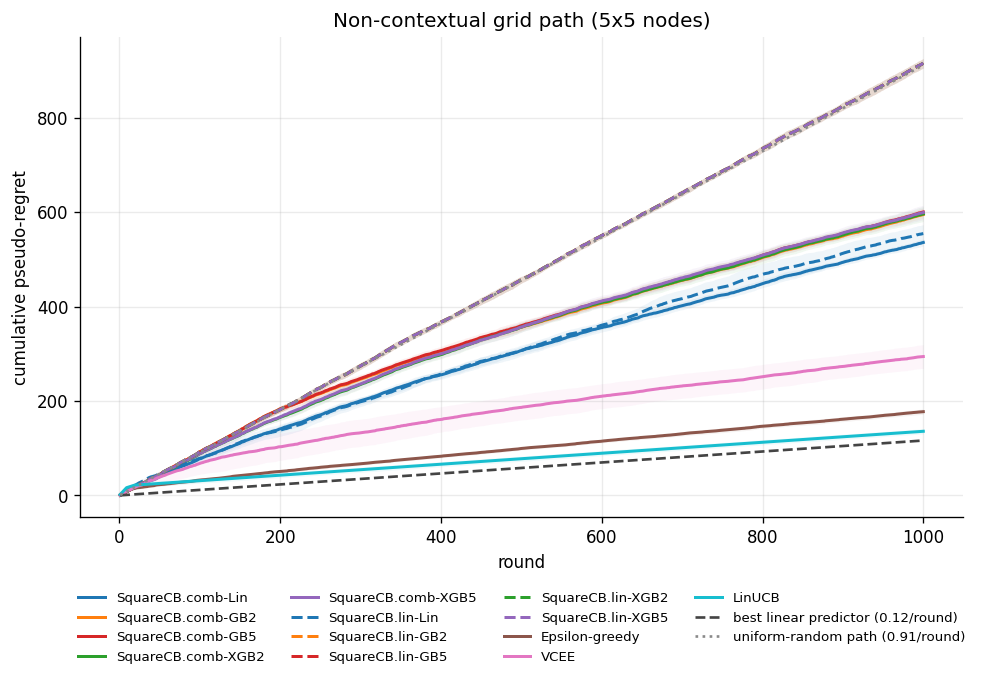

oracle,—,Lin,GB2,GB5,XGB2,XGB5
algorithm,,,,,,
SquareCB.comb,—,535.9,595.1,600.4,596.2,599.3
SquareCB.lin,—,554.7,915.4,915.4,915.4,915.4
Epsilon-greedy,177.4,—,—,—,—,—
VCEE,294.2,—,—,—,—,—
LinUCB,135.8,—,—,—,—,—


,final pseudo-regret,regret sd,reward / round,optimal-path rate (last 20%)
arm,,,,
LinUCB,135.8,7.9,4.025,0.0%
Epsilon-greedy,177.4,8.1,3.987,0.2%
VCEE,294.2,36.0,3.867,0.1%
SquareCB.comb-Lin,535.9,10.7,3.608,14.2%
SquareCB.lin-Lin,554.7,27.0,3.580,7.8%
SquareCB.comb-GB2,595.1,10.4,3.557,17.9%
SquareCB.comb-XGB2,596.2,22.7,3.549,16.3%
SquareCB.comb-XGB5,599.3,21.9,3.546,14.9%
SquareCB.comb-GB5,600.4,11.7,3.540,15.7%


In [16]:
class NonContextualGridPathEnv(GridPathEnv):
    """GridPathEnv with one fixed context and stationary edge means."""

    def __init__(self, cfg, seed):
        super().__init__(cfg, seed)
        self.fixed_x = np.asarray(cfg.noncontext_x, dtype=float)
        self.fixed_features = self.features_at(self.fixed_x)
        self.fixed_mu = self.means_at(self.fixed_x)
        self.fixed_opt = self.best_path(self.fixed_mu)

    def get_new_context(self):
        self.curr_mu = self.fixed_mu
        self.curr_r = self.rng.binomial(1, self.fixed_mu).astype(float)
        self.curr_opt = self.fixed_opt
        self.t += 1
        return Context(f"fixed-grid-{self.t}", self.fixed_features, self.K, self.L)


fixed_env = NonContextualGridPathEnv(CFG, CFG.seed0)
fixed_values = fixed_env.incidence @ fixed_env.fixed_mu
gap = np.sort(fixed_values)[-1] - np.sort(fixed_values)[-2]
fixed_refs = reference_regrets(fixed_env, [CFG.noncontext_x])
print(f"fixed context x={CFG.noncontext_x}, optimal value={fixed_values.max():.3f}, "
      f"path gap={gap:.3f}")
print("reference pseudo-regret per round: "
      + ", ".join(f"{k}={v:.3f}" for k, v in fixed_refs.items()))

side_jobs = [(name, seed) for name in ALGORITHMS for seed in seeds]
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="A worker stopped while some jobs.*")
    side_completed = Parallel(n_jobs=CFG.n_jobs)(
        delayed(run_one)(name, CFG, seed, NonContextualGridPathEnv)
        for name, seed in side_jobs)
noncontextual_runs = {name: [] for name in ALGORITHMS}
for (name, _), result in zip(side_jobs, side_completed):
    noncontextual_runs[name].append(result)
print(f"Finished non-contextual side result: {len(ALGORITHMS)} algorithms x "
      f"{CFG.n_seeds} seeds x {CFG.T:,} rounds.")

noncontextual_summary = plot_results(
    noncontextual_runs,
    f"Non-contextual grid path ({CFG.grid_size}x{CFG.grid_size} nodes)",
    "noncontextual_regret.png", refs=fixed_refs)
display(summary_matrix(noncontextual_summary).style
        .format("{:.1f}", na_rep="\u2014")
        .set_caption(f"Non-contextual: final pseudo-regret at T={CFG.T:,} "
                     f"(mean over {CFG.n_seeds} seeds). The best linear "
                     f"predictor scores "
                     f"{fixed_refs['best linear predictor'] * CFG.T:.0f} and a "
                     f"random path "
                     f"{fixed_refs['uniform-random path'] * CFG.T:.0f}."))

noncontextual_summary.drop(columns=["algorithm", "oracle"]).style.format({
    "final pseudo-regret": "{:.1f}", "regret sd": "{:.1f}",
    "reward / round": "{:.3f}",
    "optimal-path rate (last 20%)": "{:.1%}"})

## Exploration sweep: regret vs. `gamma_multiplier`

SquareCB's exploration rate is $\gamma_t=c\sqrt{Kt/L}$, and the constant $c$ (`gamma_multiplier`) is the single knob that slides it between near-uniform exploration and near-greedy exploitation. Everything above uses `CFG.gamma_multiplier = 1.0`, which is this notebook's default rather than a tuned value — `tune/sqcb_lin_optima.json` records $3$–$30$ for the arXiv datasets.

The sweep runs both SquareCB variants over `CFG.gamma_grid` for each oracle in `CFG.sweep_oracles`, in both settings, on a smaller replication budget (`CFG.sweep_seeds`). **One panel per (variant, setting)**, so the algorithm is named in the panel title and colour is free to mean the regression oracle and nothing else — line style carries no information here. Panels in a column share a $y$-range, so the two variants are directly comparable. Error bars are 95% normal intervals; the grey vertical line marks the value used in the tables above, and the two grey horizontals are the same references as before.

Two features of the result are worth naming in advance, because both look like plotting faults and neither is:

- The `SquareCB.comb` and `SquareCB.lin` panels **slope in opposite directions**. `comb` sees every played edge's reward and improves as $\gamma$ rises; `lin` sees only the aggregate path reward, and the log-det barrier is what keeps the played covariance conditioned well enough to identify per-edge means from it. Shrinking that barrier destroys identifiability, so `lin` needs *more* exploration, not less.
- In the `SquareCB.lin` / non-contextual panel the `GB5` and `XGB5` curves are **flat, identical, and sitting exactly on the uniform-random reference** (they overplot, so only one colour is visible). That is a genuine defect, not a tie: `SquareCBLin.update` trains the oracle on the *sum* of the played path's edge features but `predict` queries *single* edges, and a tree cannot extrapolate off its training support — every query lands in one leaf, the score vector is constant, and the sampler is uniform for any $\gamma$. The linear oracle is immune, which is why only those two curves are flat.

contextual: 6 arms x 7 gammas x 4 seeds
non-contextual: 6 arms x 7 gammas x 4 seeds


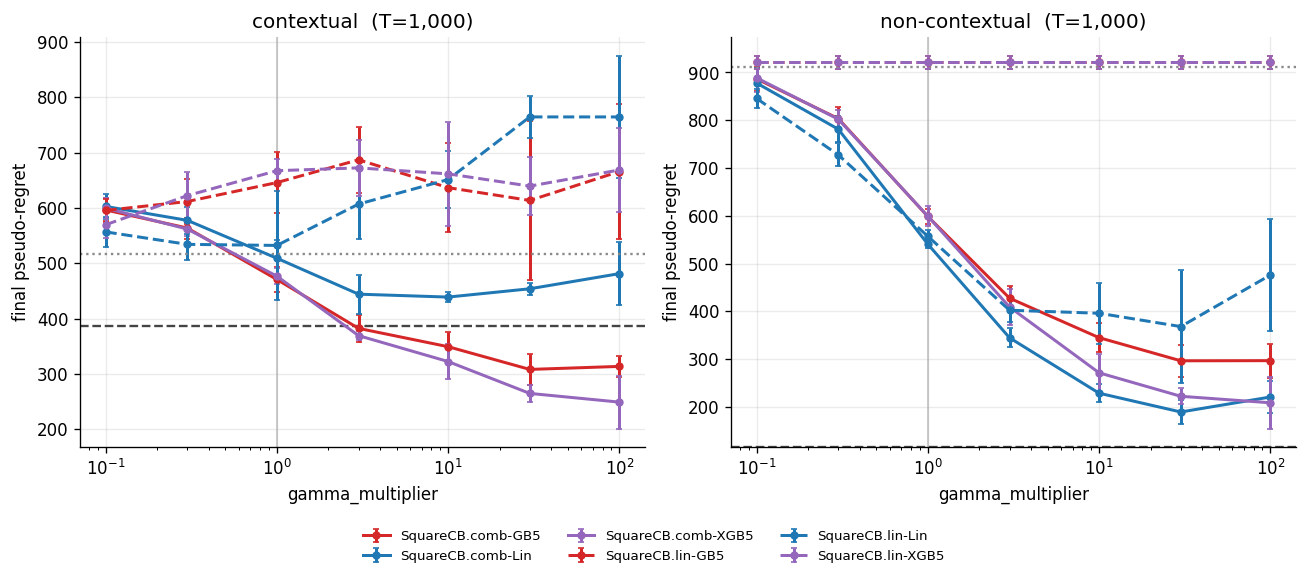

In [17]:
def gamma_sweep(env_class):
    """Final pseudo-regret for each (SquareCB variant x oracle x gamma)."""
    arms = [f"{family}-{tag}" for family in SQUARECB_FAMILIES
            for tag in CFG.sweep_oracles]
    sweep_seeds = range(CFG.seed0, CFG.seed0 + CFG.sweep_seeds)
    jobs = [(arm, gamma, seed) for arm in arms
            for gamma in CFG.gamma_grid for seed in sweep_seeds]
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="A worker stopped while some jobs.*")
        done = Parallel(n_jobs=CFG.n_jobs)(
            delayed(run_one)(arm, CFG, seed, env_class, gamma)
            for arm, gamma, seed in jobs)
    records = {}
    for (arm, gamma, _), result in zip(jobs, done):
        records.setdefault((arm, gamma), []).append(result["cum_regret"][-1])
    return pd.DataFrame([
        {"arm": arm, "gamma_multiplier": gamma,
         "final pseudo-regret": float(np.mean(v)),
         "se": (float(np.std(v, ddof=1) / np.sqrt(len(v))) if len(v) > 1 else 0.0)}
        for (arm, gamma), v in records.items()])


sweeps, sweep_refs = {}, {}
for label, env_class, refs in (("contextual", GridPathEnv, contextual_refs),
                              ("non-contextual", NonContextualGridPathEnv, fixed_refs)):
    sweeps[label], sweep_refs[label] = gamma_sweep(env_class), refs
    print(f"{label}: {2 * len(CFG.sweep_oracles)} arms x "
          f"{len(CFG.gamma_grid)} gammas x {CFG.sweep_seeds} seeds")

# One panel per (variant, setting): the algorithm is named in the panel
# title, so nothing is encoded in the line style and the "Lin" oracle can
# never be confused with the "SquareCB.lin" variant. Colour is the oracle.
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), sharex=True)
for col, label in enumerate(sweeps):
    for row, family in enumerate(SQUARECB_FAMILIES):
        ax = axes[row, col]
        for tag in CFG.sweep_oracles:
            arm = f"{family}-{tag}"
            group = (sweeps[label][sweeps[label]["arm"] == arm]
                     .sort_values("gamma_multiplier"))
            ax.errorbar(group["gamma_multiplier"], group["final pseudo-regret"],
                        yerr=1.96 * group["se"], color=ORACLE_COLORS[tag],
                        lw=1.9, marker="o", ms=5, capsize=2, label=tag)
        for name, per_round in sweep_refs[label].items():
            style, color = ref_styles[name]
            ax.axhline(per_round * CFG.T, ls=style, lw=1.4, color=color,
                       label=name if (row == 0 and col == 0) else None)
        ax.axvline(CFG.gamma_multiplier, color="#cccccc", lw=1.2, zorder=0)
        ax.set_xscale("log")
        ax.grid(alpha=0.25)
        ax.set_title(f"{family}   \u2014   {label}", fontsize=10)
        if col == 0:
            ax.set_ylabel("final pseudo-regret")
        if row == len(SQUARECB_FAMILIES) - 1:
            ax.set_xlabel("gamma_multiplier")

# Common y-range down each column so the two variants are directly comparable.
for col in range(axes.shape[1]):
    lo = min(ax.get_ylim()[0] for ax in axes[:, col])
    hi = max(ax.get_ylim()[1] for ax in axes[:, col])
    for ax in axes[:, col]:
        ax.set_ylim(lo, hi)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.03),
           ncol=5, fontsize=9, frameon=False)
fig.tight_layout()
os.makedirs(CFG.output_dir, exist_ok=True)
fig.savefig(os.path.join(CFG.output_dir, "gamma_sweep.png"), dpi=180,
            bbox_inches="tight")
plt.show()

gamma_table = (pd.concat([t.assign(setting=k) for k, t in sweeps.items()])
               .pivot(index=["setting", "arm"], columns="gamma_multiplier",
                      values="final pseudo-regret"))
gamma_table.columns = [f"{g:g}" for g in gamma_table.columns]
gamma_table.style.format("{:.0f}").set_caption(
    f"Final pseudo-regret at T={CFG.T:,} vs gamma_multiplier "
    f"({CFG.sweep_seeds} seeds). Lower is better; the tables above all use "
    f"gamma_multiplier = {CFG.gamma_multiplier:g}.")

### Reading the comparison

Both experiments are short, misspecified sanity checks rather than tuned benchmarks, and the curves should be read against the two dashed references on each plot rather than against zero.

Every oracle here is linear while $\mu$ is a Gaussian bump, so no method can drive regret to zero. In the contextual run the best linear predictor of $\mu$ on $\phi$ already forfeits $\approx0.39$ per round and a uniformly random path forfeits $\approx0.51$; the whole comparison lives in that band. A method finishing near the lower line has essentially solved the exploration problem it was given; one finishing near the upper line has not explored usefully at all. Curves are close to straight for exactly this reason — the floor is a constant per-round cost, not something that decays.

The `optimal-path rate` column deserves care under misspecification: a converged learner settles on the best path *its model can express*, which is usually not $A^*(x)$, so a low rate is expected and a high rate can even flag a method that is still exploring widely. Regret, not hit rate, is the metric.

`SquareCB.lin` receives only aggregate path feedback; the other methods observe every selected edge reward. The contextual result draws a fresh $x_t$ every round, whereas the side result fixes `CFG.noncontext_x`. Both `SquareCB` rows use the untuned default `gamma_multiplier = 1.0`; raising it materially changes where `SquareCB.comb` lands.

Edit only `CFG` to change the grid, fixed context, horizon, replications, parallelism, or output folder — with the caveat that `grid_size` above $6$ overflows the base-$K$ path hash inside `MiniMonster`, so VCEE is limited to $s\le6$.